# Medellín — Edge Betweenness Filtration

Persistent homology where edges are added from **most important** (highest betweenness) to **least important** (lowest betweenness) in 10 equal steps.

- All nodes are present from step 0.
- Edges are sorted by normalised betweenness (descending) and split into 10 quantile bins.
- Step 1 adds the top-10% most important edges; step 10 adds the bottom-10%.

In [1]:
import osmnx as ox
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
import gudhi
from pathlib import Path

def find_repo_root(start=Path.cwd()) -> Path:
    for candidate in [start.resolve(), *start.resolve().parents]:
        if (candidate / "edge_importance_ph").exists():
            return candidate
    raise FileNotFoundError(f"Could not find urban_form repository from {start.resolve()}")

REPO_ROOT = find_repo_root()
EDGE_IMPORTANCE_ROOT = REPO_ROOT / "edge_importance_ph"
ROAD_IMPORTANCE_DIR = EDGE_IMPORTANCE_ROOT / "calculate_road_importance"
FILTRATION_FIGS_DIR = EDGE_IMPORTANCE_ROOT / "filtration_with_importance" / "figs_different_cities"
FILTRATION_FIGS_DIR.mkdir(parents=True, exist_ok=True)

GRAPHML_PATH = ROAD_IMPORTANCE_DIR / "experiment_bounding_city" / "graphs" / "osmnx" / "sur_" / "America" / "medellin.graphml"
N_STEPS = 10

# Load with OSMnx so the graph retains all OSMnx metadata
G = ox.load_graphml(GRAPHML_PATH)
G_undir = ox.convert.to_undirected(G)

print(f"Directed   — nodes: {G.number_of_nodes()}, edges: {G.number_of_edges()}")
print(f"Undirected — nodes: {G_undir.number_of_nodes()}, edges: {G_undir.number_of_edges()}")

Directed   — nodes: 18629, edges: 42876
Undirected — nodes: 18629, edges: 26947


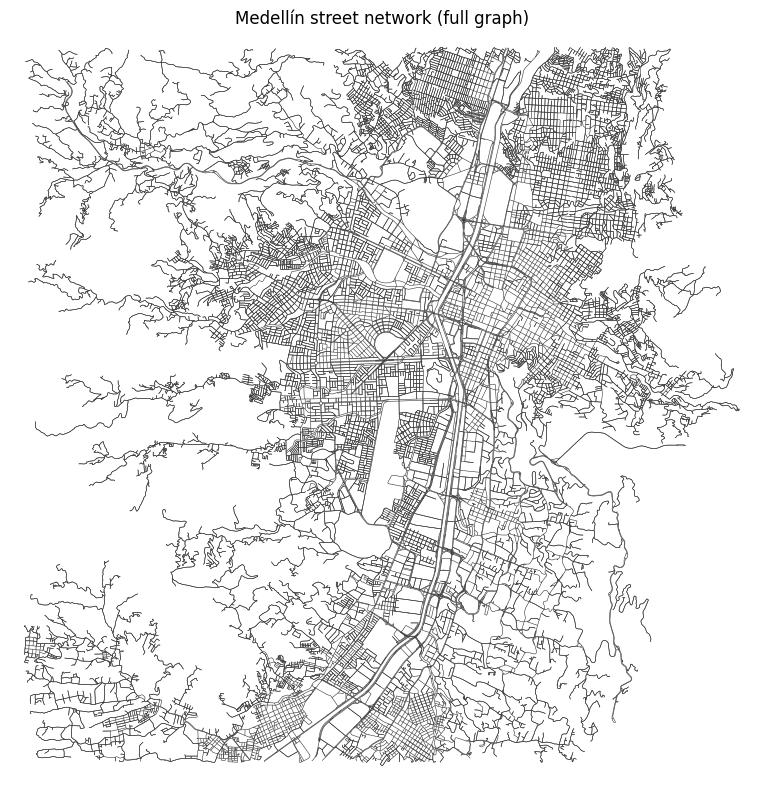

In [2]:
# ------------------------------------------------------------------
# Plot the full graph with OSMnx for a nice overview
# ------------------------------------------------------------------
fig, ax = ox.plot_graph(
    G,
    node_size=0,
    edge_linewidth=0.4,
    bgcolor="white",
    edge_color="#333333",
    show=False,
    close=False,
)
ax.set_title("Medellín street network (full graph)", fontsize=12)
plt.tight_layout()
#plt.savefig("mde_full_graph.pdf")
plt.show()

In [3]:
# ------------------------------------------------------------------
# Extract betweenness values from edge attributes.
# The graphml stores betweenness as a string; convert to float.
# Edges without the attribute get betweenness = 0.
# ------------------------------------------------------------------
raw_values = []
for u, v, data in G_undir.edges(data=True):
    val = data.get("betweenness", 0)
    try:
        raw_values.append(float(val))
    except (ValueError, TypeError):
        raw_values.append(0.0)

raw_values = np.array(raw_values)
print(f"Betweenness — min: {raw_values.min():.6f}, max: {raw_values.max():.6f}, mean: {raw_values.mean():.6f}")
print(f"Edges with betweenness > 0: {(raw_values > 0).sum()} / {len(raw_values)}")

Betweenness — min: 0.000000, max: 56357228.000000, mean: 914059.429547
Edges with betweenness > 0: 26728 / 26947


In [ ]:
# ------------------------------------------------------------------
# Assign filtration steps using a REFINED equal-width log-scale scheme.
#
# Base: N_STEPS equal-width bins on log1p(betweenness), descending
# (step 1 = highest betweenness).
#
# Refinement: the top 2 base bins are each split into 2 finer sub-bins,
# giving steps 1-4 double resolution over the high-betweenness backbone.
# Steps 5-10 cover the remaining 6 base bins unchanged.
# Total steps remains N_STEPS = 10.
# ------------------------------------------------------------------
log_values = np.log1p(raw_values)

log_max = log_values.max()
log_min = log_values.min()

base_width = (log_max - log_min) / N_STEPS   # width of one base bin
top2_lo    = log_max - 2 * base_width         # lower edge of the top-2 base bins

# 4 fine sub-bins inside the top-2 region
fine_edges   = np.linspace(top2_lo, log_max, 4)   # 5 pts -> 4 bins
# 6 coarse bins covering [log_min, top2_lo]
coarse_edges = np.linspace(log_min, top2_lo, 8)   # 7 pts -> 6 bins

# Combined: 7 + 4 = 11 points -> 10 bins, total steps = 10
all_edges = np.concatenate([coarse_edges, fine_edges[1:]])
assert len(all_edges) == N_STEPS + 1, f"Expected {N_STEPS+1} edges, got {len(all_edges)}"

def assign_step(log_b):
    """Return filtration step 1..N_STEPS (1 = most important)."""
    for step in range(1, N_STEPS + 1):
        lo = all_edges[N_STEPS - step]
        if log_b >= lo:
            return step
    return N_STEPS

# Build undirected graph H with filtration attribute on each edge
H = nx.Graph()
H.add_nodes_from(G_undir.nodes())

for (u, v, data), log_b in zip(G_undir.edges(data=True), log_values):
    step = assign_step(log_b)
    if H.has_edge(u, v):
        H[u][v]["filtration"] = min(H[u][v]["filtration"], step)
        H[u][v]["betweenness"] = max(H[u][v]["betweenness"], float(data.get("betweenness", 0)))
    else:
        H.add_edge(u, v, filtration=step, betweenness=float(data.get("betweenness", 0)))

print(f"H — nodes: {H.number_of_nodes()}, edges: {H.number_of_edges()}")
print("Steps 1-4 = top-2 base bins split in half (fine resolution)")
print("Steps 5-10 = remaining 6 base bins (coarse resolution)")

from collections import Counter
step_counts = Counter(d["filtration"] for _, _, d in H.edges(data=True))
print("\nEdges per filtration step:")
for s in range(1, N_STEPS + 1):
    lo  = np.expm1(all_edges[N_STEPS - s])
    hi  = np.expm1(all_edges[N_STEPS - s + 1])
    tag = "(fine)"   if s <= 4 else "(coarse)"
    print(f"  Step {s:2d}: {step_counts.get(s, 0):5d} edges  betweenness [{lo:.0f}, {hi:.0f}] {tag}")


H — nodes: 18629, edges: 26836
Steps 1-4 = top-2 base bins split in half (fine resolution)
Steps 5-10 = remaining 6 base bins (coarse resolution)

Edges per filtration step:
  Step  1:   157 edges  betweenness [17148243, 56357228] (fine)
  Step  2:   992 edges  betweenness [5217826, 17148243] (fine)
  Step  3:  2064 edges  betweenness [1587667, 5217826] (fine)
  Step  4:  7064 edges  betweenness [206507, 1587667] (fine)
  Step  5:  8568 edges  betweenness [26859, 206507] (coarse)
  Step  6:  6333 edges  betweenness [3493, 26859] (coarse)
  Step  7:   852 edges  betweenness [453, 3493] (coarse)
  Step  8:   279 edges  betweenness [58, 453] (coarse)
  Step  9:   211 edges  betweenness [7, 58] (coarse)
  Step 10:   316 edges  betweenness [0, 7] (coarse)


/var/folders/1z/lkjj_d294bg99hybc2v704bm0000gn/T/ipykernel_52596/392401240.py:21: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[1].legend(fontsize=8)


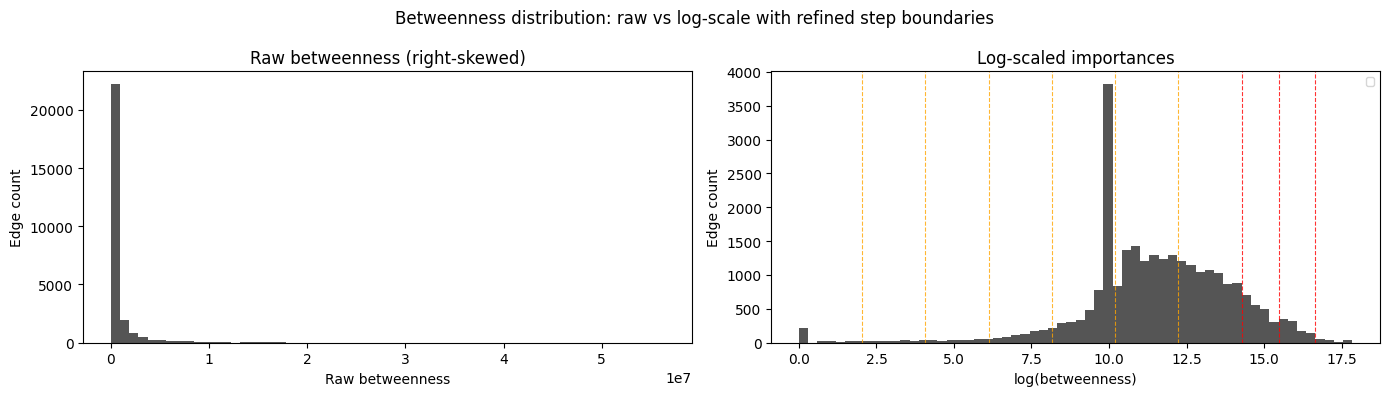

In [7]:
# ------------------------------------------------------------------
# PLOT: Raw vs log-scale betweenness distribution + step boundaries
# ------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Left: raw betweenness (shows the heavy right skew)
axes[0].hist(raw_values, bins=60, color="#555555", edgecolor="none")
axes[0].set_xlabel("Raw betweenness")
axes[0].set_ylabel("Edge count")
axes[0].set_title("Raw betweenness (right-skewed)")

# Right: log1p-transformed with refined step boundaries
axes[1].hist(log_values, bins=60, color="#555555", edgecolor="none")
for t in all_edges[1:-1]:
    color = "red" if t >= top2_lo else "orange"
    axes[1].axvline(t, color=color, linewidth=0.8, linestyle="--", alpha=0.8)

axes[1].set_xlabel("log(betweenness)")
axes[1].set_ylabel("Edge count")
axes[1].set_title("Log-scaled importances")
axes[1].legend(fontsize=8)

plt.suptitle("Betweenness distribution: raw vs log-scale with refined step boundaries", fontsize=12)
plt.tight_layout()
#plt.savefig("mde_betweenness_distribution.pdf")
plt.show()


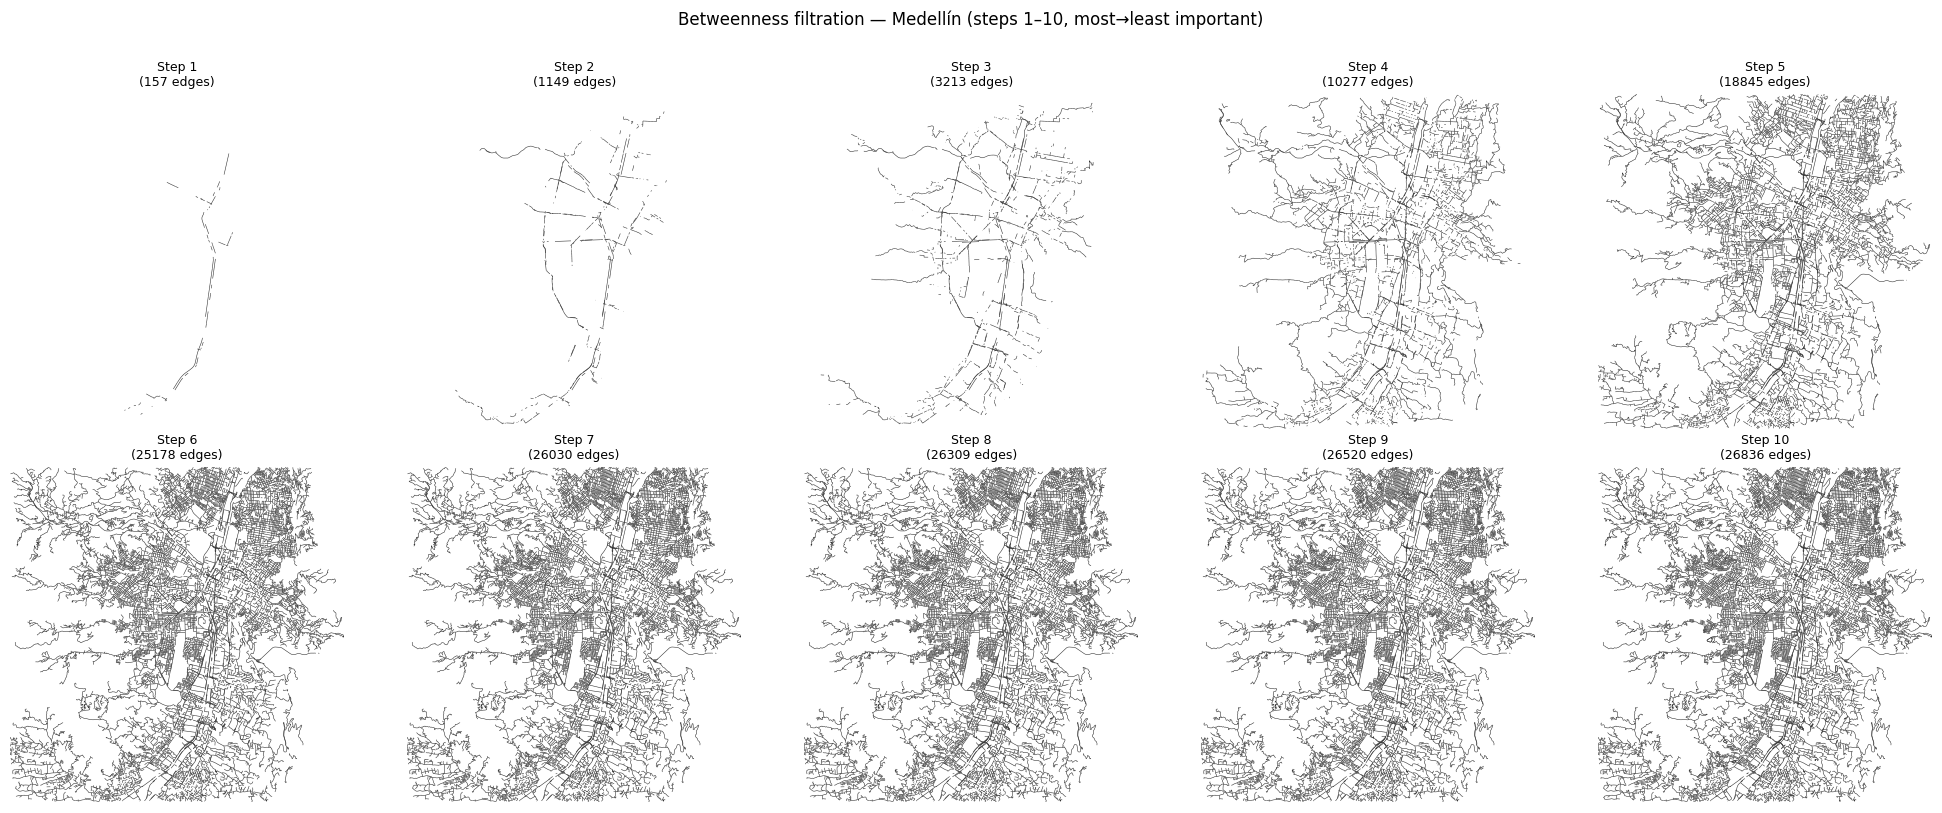

In [20]:
# ------------------------------------------------------------------
# PLOT: Cumulative filtration snapshots using OSMnx plot_graph
# Each panel shows all edges added up to that step.
# ------------------------------------------------------------------
nodes_gdf, edges_gdf = ox.graph_to_gdfs(G)

cols = 5
rows = 2
fig, axes = plt.subplots(rows, cols, figsize=(20, 8))
axes = axes.flatten()

xmin, ymin, xmax, ymax = edges_gdf.total_bounds

for step in range(1, N_STEPS + 1):
    ax = axes[step - 1]

    # Edges active at this step
    active_edges = {(u, v) for u, v, d in H.edges(data=True) if d["filtration"] <= step}

    # Filter the GeoDataFrame to active edges (match on u, v ignoring key)
    mask = edges_gdf.index.map(lambda idx: (idx[0], idx[1]) in active_edges)
    subset = edges_gdf[mask]

    if not subset.empty:
        subset.plot(ax=ax, linewidth=0.4, color="#333333")

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_title(f"Step {step}\n({len(active_edges)} edges)", fontsize=9)
    ax.set_axis_off()

plt.suptitle("Betweenness filtration — Medellín (steps 1–10, most→least important)",
             fontsize=12, y=1.01)
plt.tight_layout()
#plt.savefig("mde_betweenness_filtration_snapshots.png")
plt.show()

In [7]:
# ------------------------------------------------------------------
# BUILD GUDHI SIMPLEX TREE
# All nodes at filtration 0; edges at their assigned step.
# ------------------------------------------------------------------
st = gudhi.SimplexTree()

node_to_int = {node: i for i, node in enumerate(H.nodes())}

for node in H.nodes():
    st.insert([node_to_int[node]], filtration=0.0)

for u, v, data in H.edges(data=True):
    st.insert([node_to_int[u], node_to_int[v]], filtration=float(data["filtration"]))

print("Simplex tree summary")
print("  Dimension  :", st.dimension())
print("  Num vertices:", st.num_vertices())
print("  Num simplices:", st.num_simplices())

Simplex tree summary
  Dimension  : 1
  Num vertices: 29761
  Num simplices: 66281


In [8]:
# ------------------------------------------------------------------
# COMPUTE PERSISTENCE
# ------------------------------------------------------------------
diag = st.persistence(homology_coeff_field=2, persistence_dim_max=True)

h0 = st.persistence_intervals_in_dimension(0)
h1 = st.persistence_intervals_in_dimension(1)

h1_finite = h1[np.isfinite(h1).all(axis=1)] if len(h1) > 0 else np.empty((0, 2))

print(f"H0 intervals: {len(h0)}")
print(f"H1 intervals: {len(h1)}  (finite: {len(h1_finite)})")

if len(h1_finite) > 0:
    h1_lengths = h1_finite[:, 1] - h1_finite[:, 0]
    print("\nFinite H1 bar lengths (sample):")
    print(h1_lengths[:20])

bettis = st.betti_numbers()
print("\nBetti numbers:", bettis)

H0 intervals: 29761
H1 intervals: 6760  (finite: 0)

Betti numbers: [1, 6760]


In [9]:
# ------------------------------------------------------------------
# Replace inf death values with N_STEPS + 1 for plotting
# ------------------------------------------------------------------
replacement = N_STEPS + 1
h0_plot = h0.copy()
h1_plot = h1.copy()
h0_plot[np.isinf(h0_plot)] = replacement
h1_plot[np.isinf(h1_plot)] = replacement

In [10]:
# ------------------------------------------------------------------
# GRAPH-THEORETIC DIAGNOSTICS
# ------------------------------------------------------------------
c = nx.number_connected_components(H)
m = H.number_of_edges()
n_nodes = H.number_of_nodes()
cycle_rank = m - n_nodes + c

print("Graph-theoretic diagnostics (full graph)")
print(f"  Nodes              : {n_nodes}")
print(f"  Edges              : {m}")
print(f"  Connected components: {c}")
print(f"  Cycle rank         : {cycle_rank}")

print("\nStep-by-step filtration summary")
for t in range(1, N_STEPS + 1):
    edges_t = [(u, v) for u, v, d in H.edges(data=True) if d["filtration"] <= t]
    G_t = nx.Graph()
    G_t.add_nodes_from(H.nodes())
    G_t.add_edges_from(edges_t)
    n_t = G_t.number_of_nodes()
    m_t = G_t.number_of_edges()
    c_t = nx.number_connected_components(G_t)
    cr_t = m_t - n_t + c_t
    print(f"  Step {t:2d}: nodes={n_t}, edges={m_t:5d}, components={c_t:4d}, cycle_rank={cr_t}")

Graph-theoretic diagnostics (full graph)
  Nodes              : 29761
  Edges              : 36600
  Connected components: 1
  Cycle rank         : 6840

Step-by-step filtration summary
  Step  1: nodes=29761, edges=  365, components=29398, cycle_rank=2
  Step  2: nodes=29761, edges= 1707, components=28123, cycle_rank=69
  Step  3: nodes=29761, edges= 3391, components=26585, cycle_rank=215
  Step  4: nodes=29761, edges= 5622, components=24577, cycle_rank=438
  Step  5: nodes=29761, edges=15111, components=16364, cycle_rank=1714
  Step  6: nodes=29761, edges=34164, components=  36, cycle_rank=4439
  Step  7: nodes=29761, edges=35327, components=  14, cycle_rank=5580
  Step  8: nodes=29761, edges=35744, components=  12, cycle_rank=5995
  Step  9: nodes=29761, edges=36091, components=   9, cycle_rank=6339
  Step 10: nodes=29761, edges=36600, components=   1, cycle_rank=6840


<Figure size 700x600 with 0 Axes>

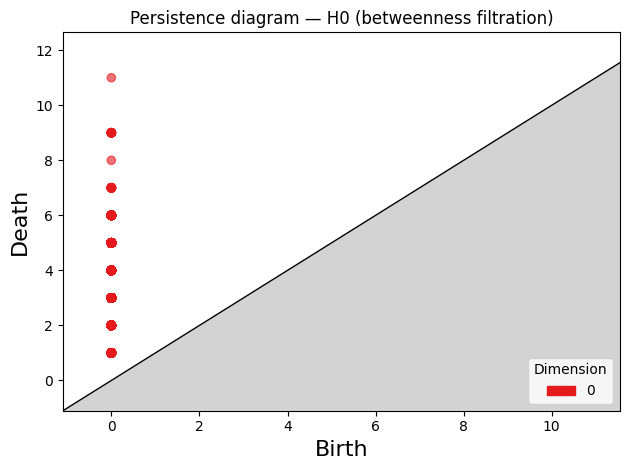

<Figure size 700x600 with 0 Axes>

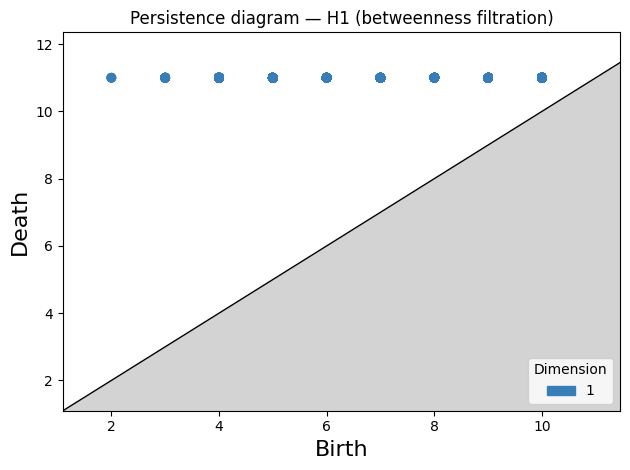

In [77]:
# ------------------------------------------------------------------
# PERSISTENCE DIAGRAMS — H0 and H1
# ------------------------------------------------------------------
if len(h0_plot) > 0:
    h0_diag = [(0, (b, d)) for b, d in h0_plot]
    plt.figure(figsize=(7, 6))
    gudhi.plot_persistence_diagram(h0_diag)
    plt.title("Persistence diagram — H0 (betweenness filtration)")
    plt.tight_layout()
    #plt.savefig("mde_betweenness_h0_diagram.pdf")
    plt.show()
else:
    print("No H0 intervals.")

if len(h1_plot) > 0:
    h1_diag = [(1, (b, d)) for b, d in h1_plot]
    plt.figure(figsize=(7, 6))
    gudhi.plot_persistence_diagram(h1_diag)
    plt.title("Persistence diagram — H1 (betweenness filtration)")
    plt.tight_layout()
    #plt.savefig("mde_betweenness_h1_diagram.pdf")
    plt.show()
else:
    print("No H1 intervals.")

<Figure size 1000x400 with 0 Axes>

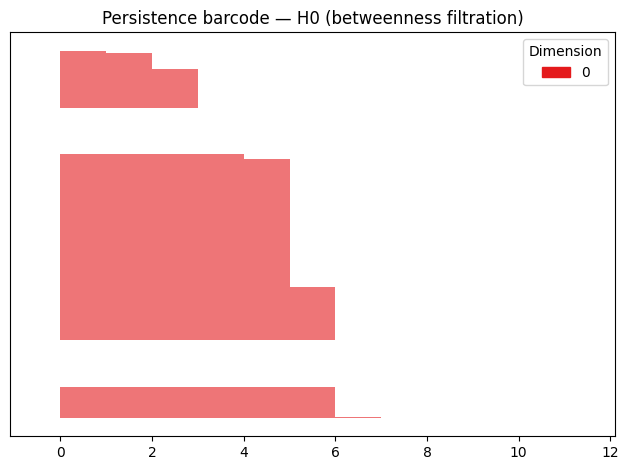

<Figure size 1000x400 with 0 Axes>

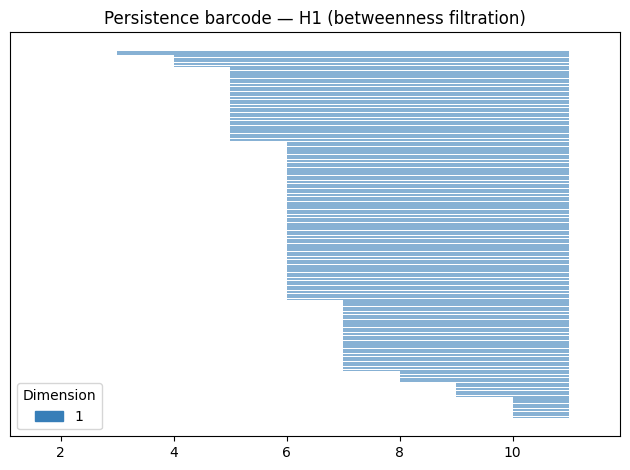

In [78]:
# ------------------------------------------------------------------
# PERSISTENCE BARCODES — H0 and H1
# ------------------------------------------------------------------
if len(h0_plot) > 0:
    h0_diag = [(0, (b, d)) for b, d in h0_plot]
    plt.figure(figsize=(10, 4))
    gudhi.plot_persistence_barcode(h0_diag)
    plt.title("Persistence barcode — H0 (betweenness filtration)")
    plt.tight_layout()
    #plt.savefig("mde_betweenness_h0_barcode.pdf")
    plt.show()

if len(h1_plot) > 0:
    h1_diag = [(1, (b, d)) for b, d in h1_plot]
    plt.figure(figsize=(10, 4))
    gudhi.plot_persistence_barcode(h1_diag)
    plt.title("Persistence barcode — H1 (betweenness filtration)")
    plt.tight_layout()
    #plt.savefig("mde_betweenness_h1_barcode.pdf")
    plt.show()

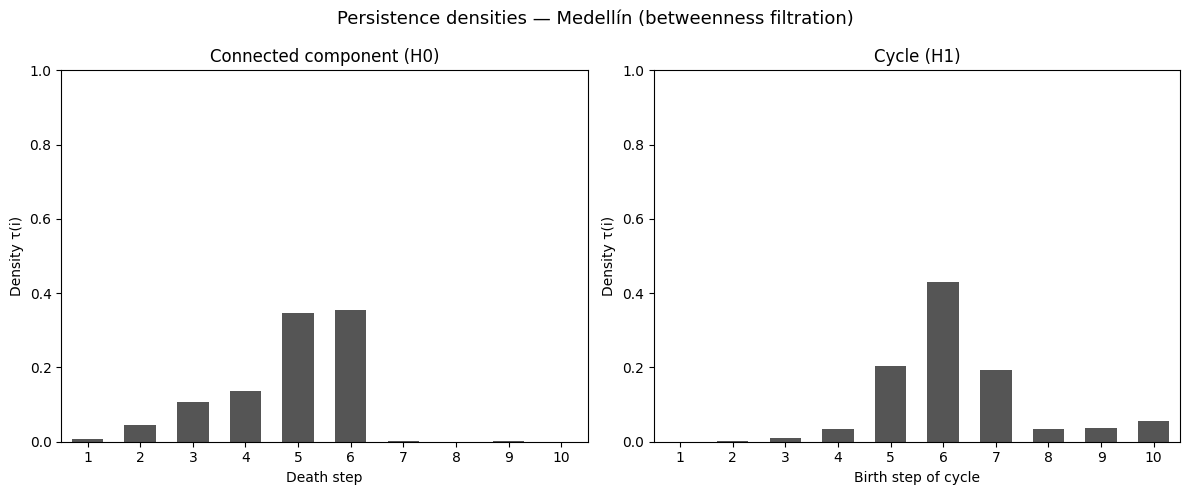

In [79]:
# ------------------------------------------------------------------
# PERSISTENCE DENSITY
# τ(i) = fraction of bars with persistence length == i
# H0: x-axis = death step (when component merges)
# H1: x-axis = birth step (when cycle appears), reversed so
#     leftmost bar = cycles born at the most-important step
# ------------------------------------------------------------------
def persistence_density(intervals, max_persistence=None):
    finite = intervals[np.isfinite(intervals).all(axis=1)] if len(intervals) > 0 else np.empty((0, 2))
    if len(finite) == 0:
        return np.array([]), np.array([])
    lengths = (finite[:, 1] - finite[:, 0]).astype(int)
    total = len(finite)
    if max_persistence is None:
        max_persistence = int(lengths.max())
    i_values = np.arange(1, max_persistence + 1)
    density = np.array([np.sum(lengths == i) / total for i in i_values])
    return i_values, density


fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (intervals, label, dim) in zip(axes, [
    (h0_plot, "Connected component (H0)", "H0"),
    (h1_plot, "Cycle (H1)",               "H1"),
]):
    i_vals, dens = persistence_density(intervals, max_persistence=N_STEPS)

    if dim == "H1":
        dens = dens[::-1]  # reverse so step 1 = most important

    if len(i_vals) == 0:
        ax.set_title(f"No finite {dim} intervals")
        continue

    ax.bar(i_vals, dens, color="#555555", width=0.6)
    ax.set_xlim(0.5, N_STEPS + 0.5)
    ax.set_ylim(0, 1.0)
    ax.set_xticks(i_vals)
    ax.set_xlabel("Death step" if dim == "H0" else "Birth step of cycle")
    ax.set_ylabel("Density τ(i)")
    ax.set_title(label)

plt.suptitle("Persistence densities — Medellín (betweenness filtration)", fontsize=13)
plt.tight_layout()
#plt.savefig("mde_betweenness_densit_7500_box.pdf")
plt.show()

In [80]:
dens

array([0.        , 0.00151057, 0.00927924, 0.03344842, 0.20522227,
       0.42965041, 0.19249029, 0.03388002, 0.03754855, 0.05697022])

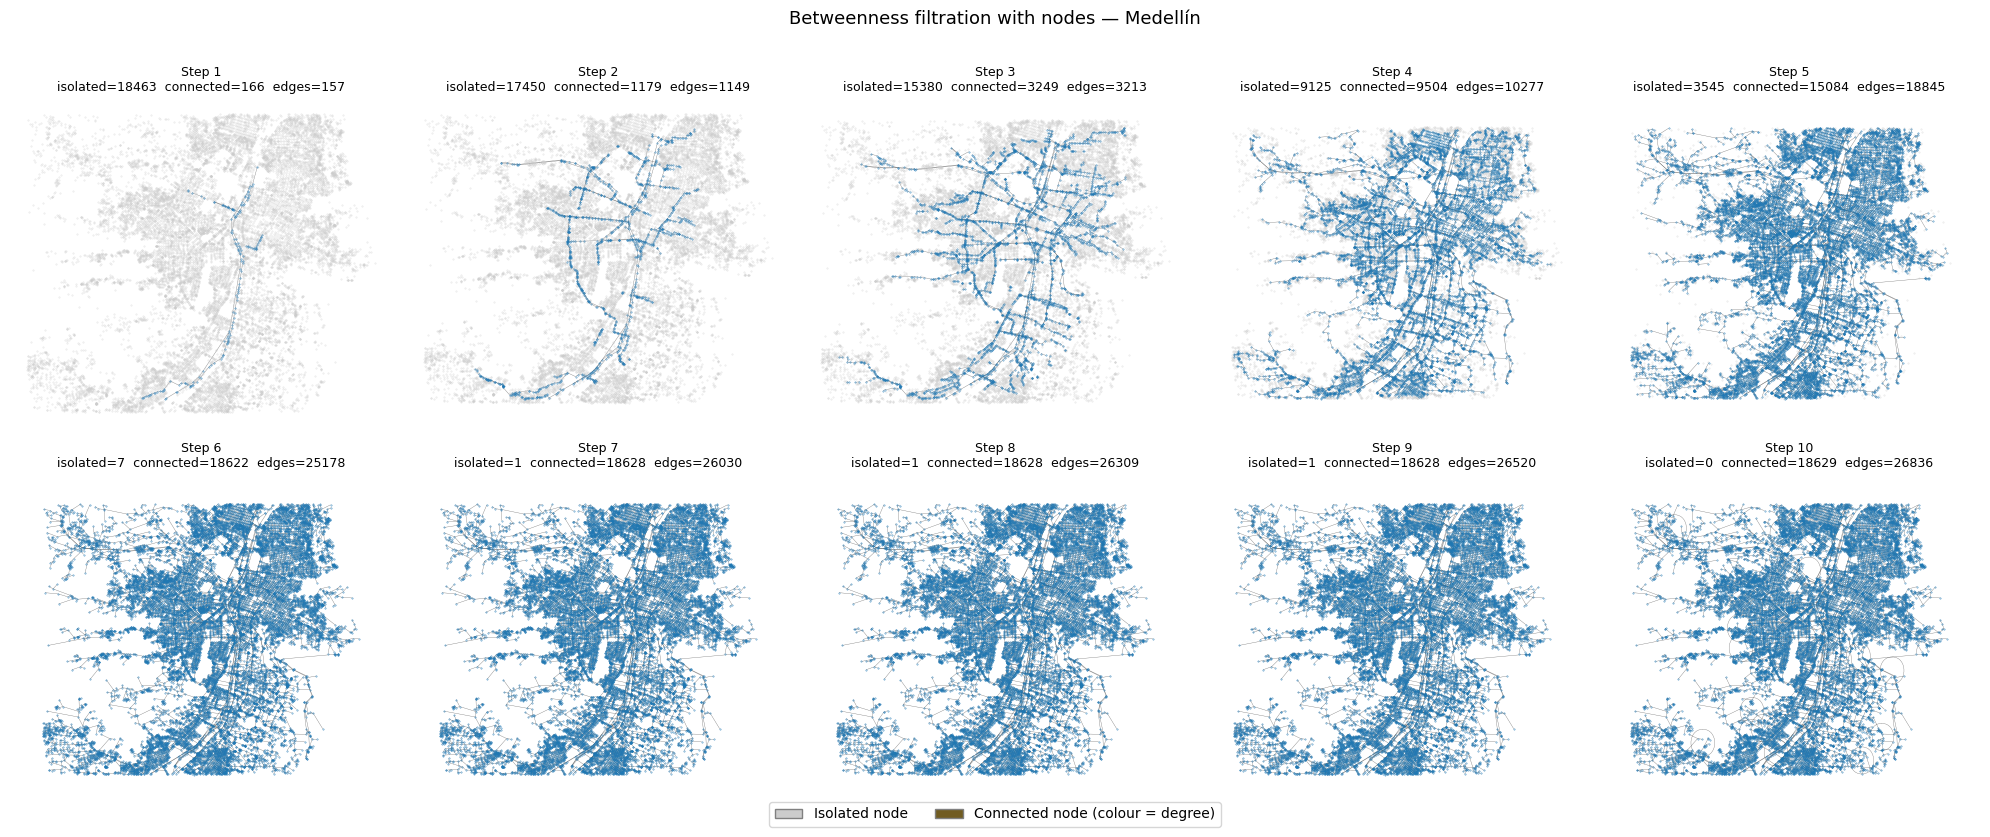

In [23]:
# ------------------------------------------------------------------
# FILTRATION PLOT WITH NODES — using OSMnx graph_to_gdfs for positions
# Node colour = degree at each step; isolated nodes shown in grey.
# ------------------------------------------------------------------
import matplotlib.patches as mpatches

# Node positions from OSMnx GeoDataFrame
pos = {node: (data["x"], data["y"]) for node, data in G.nodes(data=True)
       if "x" in data and "y" in data}

cols = 5
rows = 2
fig, axes = plt.subplots(rows, cols, figsize=(20, 8))
axes = axes.flatten()

for step in range(1, N_STEPS + 1):
    ax = axes[step - 1]
    edges_t = [(u, v) for u, v, d in H.edges(data=True) if d["filtration"] <= step]

    G_t = nx.Graph()
    G_t.add_nodes_from(H.nodes())
    G_t.add_edges_from(edges_t)

    degrees = dict(G_t.degree())
    isolated = [n for n, d in degrees.items() if d == 0 and n in pos]
    connected = [n for n, d in degrees.items() if d > 0 and n in pos]
    valid_edges = [(u, v) for u, v in G_t.edges() if u in pos and v in pos]

    nx.draw_networkx_edges(G_t, pos, edgelist=valid_edges, ax=ax,
                           edge_color="#333333", width=0.25, alpha=0.7)
    if isolated:
        nx.draw_networkx_nodes(G_t, pos, nodelist=isolated, ax=ax,
                               node_size=0.1, node_color="#cccccc", alpha=0.6)
    if connected:
        #deg_vals = np.array([degrees[n] for n in connected], dtype=float)
        nx.draw_networkx_nodes(G_t, pos, nodelist=connected, ax=ax,
                               node_size=0.1, alpha=0.9)

    ax.set_title(
        f"Step {step}\nisolated={len(isolated)}  connected={len(connected)}  edges={len(valid_edges)}",
        fontsize=9
    )
    ax.set_axis_off()

legend_handles = [
    mpatches.Patch(facecolor="#cccccc", edgecolor="grey", label="Isolated node"),
    mpatches.Patch(facecolor="#715c21", edgecolor="grey", label="Connected node (colour = degree)"),
]
fig.legend(handles=legend_handles, loc="lower center", ncol=2, fontsize=10,
           bbox_to_anchor=(0.5, -0.02))
plt.suptitle("Betweenness filtration with nodes — Medellín", fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(FILTRATION_FIGS_DIR / "med_betweenes_with_nodes.pdf")
plt.show()